# Lepton-jet reconstruction efficiency: the modelling with the corrections applied

Step 3 of [`lj_reco_efficiency.md`](lj_reco_efficiency.md). The lepton jets are corrected per
constituent: each PF muon, DSA muon, electron and photon of a selected lepton jet carries its scale
factor (`sidm/configs/corrections.yaml`), with its uncertainty:

| constituent | scale factor | measured with |
|---|---|---|
| PF muon | Loose ID (`muon_id`) | MUO, J/ψ and Z tag and probe |
| DSA muon | reconstruction and displaced ID (`dsa_muon_id`) | this study, [`10_dsa_prompt_data.ipynb`](10_dsa_prompt_data.ipynb) |
| electron | reconstruction (`electron_reco`) | EGM |
| photon | pixel-seed veto (`photon_pixel_veto`) | EGM |

This notebook compares the data of the control samples with the simulation with those corrections
applied, and sets the additional systematic per lepton jet that covers what the corrections per
constituent leave: the lepton-jet clustering, the lepton-jet cuts and the identifications without a
scale factor.

**Simulation.** Campaign `lj_reco_cr_v4` (every background): each passing probe is weighted by the
scale factors of the constituents of the lepton jet that makes it pass, or of its DSA muons for the
DSA probes, as the analysis weights its selected lepton jets. The `_sf` histograms hold this on an
`sf` axis: `none` (no scale factor), `nominal`, and each correction shifted up or down. The event
weight holds only the event-level corrections, so no scale factor enters twice. The passing fraction
with the corrections is the weighted passing probes over all the probes unweighted
(`systematics_study.corrected_efficiency`): a scale factor changes the probability to pass, not the
number of probes.

**Data.** Read through the safety tables, as in notebooks 08 and 10: the $J/\psi$ probes against
$p_T$ and $\Delta R$ (`lj_reco_cr_data_v1`), the FSR photons and the $J/\psi$ vertex displacement
(`lj_reco_cr_data_v2`), and the DSA probes (`dsa_prompt_data_v1`, 2018C only). No new data are read,
and the simulation is compared in the regions the data step reads.

**The additional systematic.** For each lepton-jet type, the data/simulation ratio $r$ with the
corrections applied is taken over the measured range above the turn-on, and in the measured bins
nearest to the signal (notebook 11: muon-type lepton jets lie mostly beyond 15 cm, below
$\Delta R$ = 0.03 and many above 300 GeV, egamma-type ones above 120 GeV). Where every nearest bin
agrees with the whole range within two standard deviations, the whole range is used; otherwise the
nearest bin that does not agree. The size is $\max(|1 - r|, \sigma_r)$, one log-normal term per
lepton-jet type (`CMS_ljreco_mu`, `CMS_ljreco_egm` in `systematics.yaml`, kind `per_lj`).

In [1]:
import os, shutil, sys, tempfile, json, warnings
from pathlib import Path
import numpy as np
import hist
import matplotlib.pyplot as plt

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # on the path through systematics_study  # pylint: disable=import-error

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)

SIM_DIR = sysstudy.eos_url(sysstudy.LJ_CR_V4_DIR)                 # merged outputs of lj_reco_cr_v4
OUTPUT_DIR = sysstudy.eos_url(sysstudy.LJ_CLOSURE_RESULTS_DIR)    # figures, ratios and sizes
if not sysstudy.list_coffea(SIM_DIR):
    raise FileNotFoundError(f"No merged outputs in {SIM_DIR} yet: run the campaign lj_reco_cr_v4 "
                            "(condor/README.md, section 23)")
WORK = Path(tempfile.mkdtemp(prefix="lj_corrected_closure_"))   # removed at the end
JPSI, VTX, FSR = "J/psi -> mumu", "J/psi -> mumu, vertex", "Z -> mumu gamma, FSR"
Z_DSA, JPSI_DSA = "Z -> mumu, DSA", "J/psi -> mumu, DSA"
# the data of each control sample: (merged outputs, safety table, the specs it holds)
DATA = {"lj_reco_cr_data_v1": (sysstudy.LJ_CR_DATA_DIR, sysstudy.LJ_CR_RESULTS_DIR, {JPSI: sysstudy.LJ_CR[JPSI]}),
        "lj_reco_cr_data_v2": (sysstudy.LJ_CR_DATA_V2_DIR, sysstudy.LJ_CR_V3_RESULTS_DIR, sysstudy.LJ_CR_V3),
        "dsa_prompt_data_v1": (sysstudy.DSA_DATA_DIR, sysstudy.DSA_RESULTS_DIR, sysstudy.DSA_CR)}
SPECS = {cr: spec for _, _, specs in DATA.values() for cr, spec in specs.items()}
DY = sysstudy.LJ_CR_GROUPS[r"DY$\to\ell\ell$"]
CORRECTIONS = ("muon_id", "dsa_muon_id", "electron_reco", "photon_pixel_veto")
ABOVE30 = {"probe_pt": slice(hist.loc(30), None, sum)}
ABOVE40 = {"probe_pt": slice(hist.loc(40), None, sum)}
ABOVE50 = {"probe_pt": slice(hist.loc(50), None, sum)}
CONVERTED = {"probe_r9": slice(None, hist.loc(0.94), sum)}
UNCONVERTED = {"probe_r9": slice(hist.loc(0.94), None, sum)}
TWO = ("n_dsa", (2,))              # J/psi pairs: both muons with their own DSA muon
PLAIN, CORRECTED = "simulation", "simulation with scale factors"


def save(fig, name):
    """Write a figure into the working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK / f"{name}{suffix}", bbox_inches="tight")


def compare(data_h, sim_h, spec, axis, sel=None, passing=("passing", (1,)), reference=PLAIN):
    """{data, simulation without and with the scale factors: probe_efficiency} against one axis,
    for the probes that sel keeps"""
    sel = sel or {}
    return {"data": sysstudy.probe_efficiency(data_h[sel], spec, axis, passing),
            reference: sysstudy.probe_efficiency(sim_h[{**sel, "sf": "none"}], spec, axis, passing),
            f"{reference} with scale factors": sysstudy.corrected_efficiency(sim_h[sel], spec, axis, "nominal",
                                                                             passing)}


def report(name, ratios):
    """Print the corrected ratios of one region (corrected_ratios) with the effect of each shift"""
    (r0, u0), (r1, u1) = ratios["none"], ratios["nominal"]
    shifts = ", ".join(f"{c} {ratios[c + 'Up'][0] - r1:+.4f}/{ratios[c + 'Down'][0] - r1:+.4f}"
                       for c in CORRECTIONS if c + "Up" in ratios
                       and abs(ratios[c + "Up"][0] - r1) + abs(ratios[c + "Down"][0] - r1) > 1e-5)
    print(f"{name:52s}: data/simulation {r0:.4f} +- {u0:.4f} without, {r1:.4f} +- {u1:.4f} with scale factors"
          + (f" (shifts: {shifts})" if shifts else ""))


closure = {}   # region: corrected_ratios, written to EOS

## 1. Inputs

The data through their safety tables (`lj_cr_data` stops at any region a table does not mark safe),
the simulation of `lj_reco_cr_v4` with the same regions set to zero. Below, per control sample, the
probes after the sideband subtraction in data and in the simulation without and with the scale
factors.

In [2]:
data, row_of = {}, {}
for campaign, (directory, results, specs) in DATA.items():
    rows = sysstudy.lj_cr_verdicts(results)
    data.update(sysstudy.lj_cr_data(rows, sysstudy.eos_url(directory), specs=specs))
    row_of.update({cr: rows for cr in specs})
sim_inputs = sysstudy.lj_cr_inputs(SIM_DIR, specs=sysstudy.with_sf(SPECS))
for per in sim_inputs["background"].values():   # the regions the data step reads, in the simulation too
    for cr, spec in SPECS.items():
        sysstudy.zero_unreadable(per[cr], row_of[cr], cr, spec.get("split", "probe_pt"))
sim = {cr: sum(per[cr] for per in sim_inputs["background"].values()) for cr in SPECS}
dy = {cr: sum(sim_inputs["background"][s][cr] for s in DY if s in sim_inputs["background"]) for cr in SPECS}
for cr, spec in SPECS.items():
    (lo, hi), sidebands = spec["peak"], spec["sidebands"]
    k = (hi - lo) / sum(b - a for a, b in sidebands)
    trig = {a.name: sum for a in data[cr].axes if a.name in sysstudy.DSA_TRIGGERS}
    for label, h in (("data", data[cr][trig]), ("simulation, no SF", sim[cr][{**trig, "sf": "none"}]),
                     ("simulation, SF", sim[cr][{**trig, "sf": "nominal"}])):
        peak = sysstudy.mass_window(h, spec["mass"], lo, hi).sum(flow=True).value
        side = sum(sysstudy.mass_window(h, spec["mass"], a, b).sum(flow=True).value for a, b in sidebands)
        print(f"{cr:24s} {label:18s}: {peak - k * side:11.4g} probes after the subtraction")

J/psi -> mumu            data              :   3.271e+05 probes after the subtraction
J/psi -> mumu            simulation, no SF :   3.829e+05 probes after the subtraction
J/psi -> mumu            simulation, SF    :   3.741e+05 probes after the subtraction
Z -> mumu gamma, FSR     data              :        9983 probes after the subtraction
Z -> mumu gamma, FSR     simulation, no SF :        9606 probes after the subtraction
Z -> mumu gamma, FSR     simulation, SF    :        9544 probes after the subtraction
J/psi -> mumu, vertex    data              :    3.26e+05 probes after the subtraction
J/psi -> mumu, vertex    simulation, no SF :   3.822e+05 probes after the subtraction
J/psi -> mumu, vertex    simulation, SF    :   3.734e+05 probes after the subtraction
Z -> mumu, DSA           data              :   6.683e+06 probes after the subtraction
Z -> mumu, DSA           simulation, no SF :   5.655e+07 probes after the subtraction
Z -> mumu, DSA           simulation, SF    :    5.03e+

**Interpretation.** Every control sample has its probes in data and in the simulation. With the
scale factors, the weighted sum of the simulated probes falls by 2.3% for the $J/\psi$ pairs, 0.6% for
the FSR photons, 11% for the $Z \to \mu\mu$ DSA probes and 15% for the $J/\psi$ DSA probes: only
passing probes carry the factors, and the DSA-muon factor (0.76 to 0.89) is the only one far from
one. The DSA data are 2018C alone, about a ninth of the simulation, which is normalized to the whole
year; the comparisons below use passing fractions only.

## 2. Muon-type lepton jets: J/ψ → μμ

The fraction of $J/\psi$ pairs with a selected muon-type lepton jet, in data and in the simulation
without and with the scale factors: against the pair's $p_T$, against $\Delta R(\mu\mu)$ above
50 GeV, and against the displacement of the fitted vertex above 50 GeV. The ratio panel shows
data/simulation without (open squares) and with (filled triangles) the scale factors.

J/psi -> mumu, all probes, against probe_pt:  data | simulation with scale factors | ratio
   20-30: 0.3795 +- 0.0332 | 1.1879 +- 1.4125 | 0.3194 +- 0.3809
   30-40: 0.6912 +- 0.0092 | 0.7297 +- 0.1035 | 0.9472 +- 0.1349
   40-50: 0.8181 +- 0.0062 | 0.8626 +- 0.0392 | 0.9484 +- 0.0437
   50-60: 0.9645 +- 0.0013 | 0.9487 +- 0.0149 | 1.0167 +- 0.0160
   60-80: 0.9850 +- 0.0005 | 0.9831 +- 0.0116 | 1.0019 +- 0.0118
   80-100: 0.9859 +- 0.0008 | 0.9749 +- 0.0035 | 1.0113 +- 0.0037
   100-150: 0.9873 +- 0.0014 | 0.9633 +- 0.0041 | 1.0249 +- 0.0046
   150-300: 0.9874 +- 0.0057 | 0.9863 +- 0.0577 | 1.0012 +- 0.0588
J/psi -> mumu, $p_T$ > 50 GeV, against probe_dR:  data | simulation with scale factors | ratio
   0-0.01: nan +- nan | -0.7013 +- 1.7066 | nan +- nan
   0.01-0.02: 0.7730 +- 0.1393 | 0.3118 +- 0.2383 | 2.4794 +- 1.9468
   0.02-0.03: 0.9256 +- 0.0306 | 0.8456 +- 0.0554 | 1.0945 +- 0.0803
   0.03-0.05: 0.9884 +- 0.0037 | 0.9783 +- 0.0310 | 1.0104 +- 0.0322
   0.05-0.08: 0.9885 +- 0.0

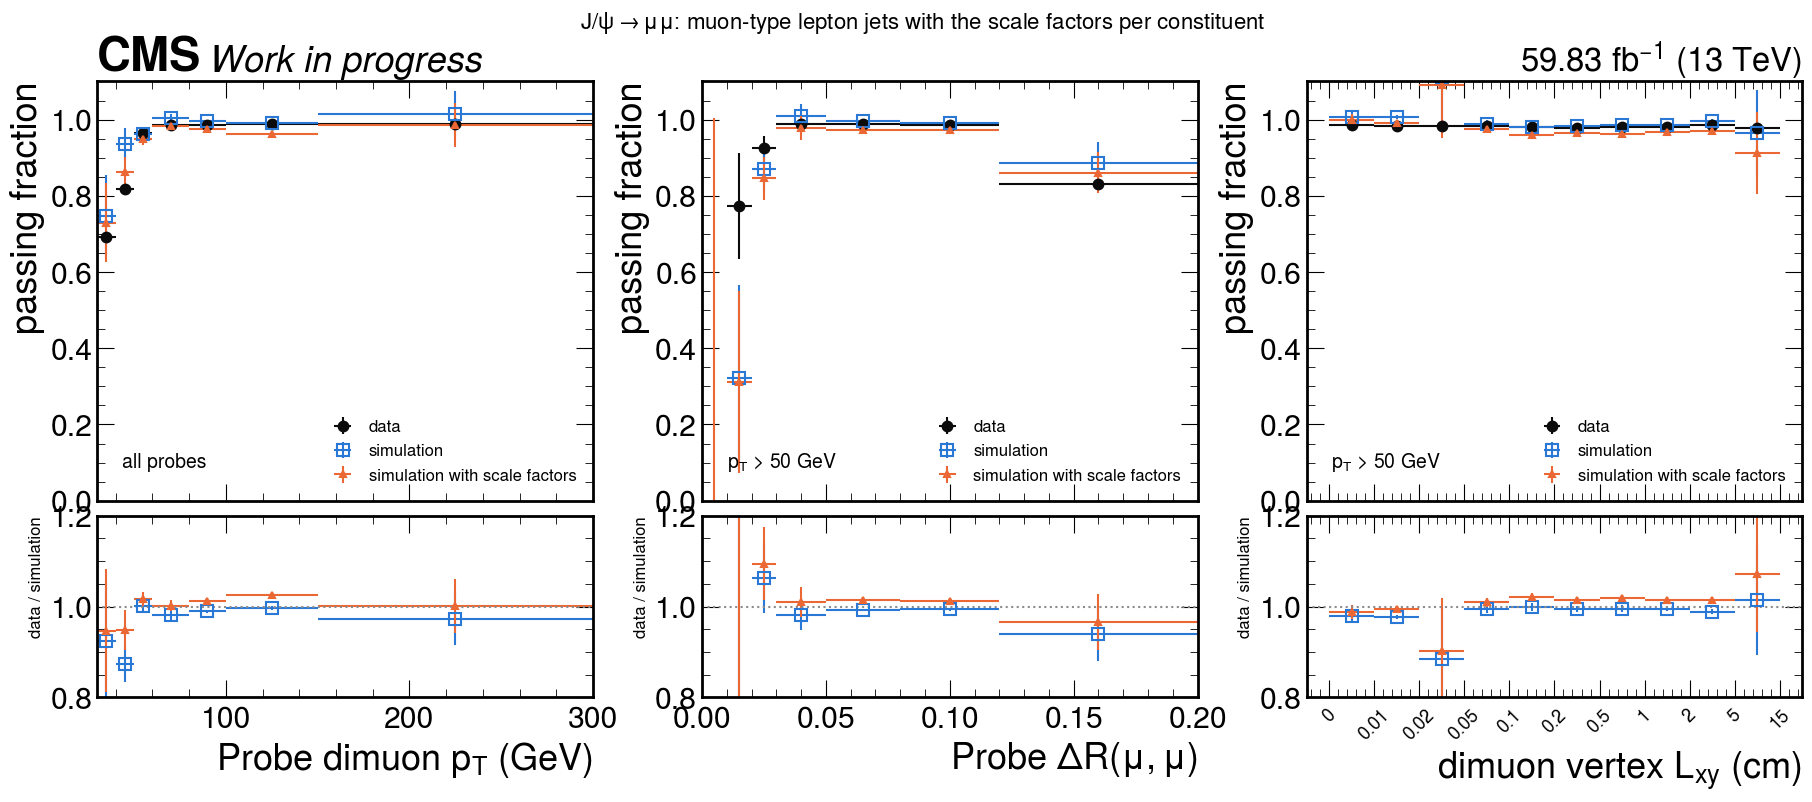

J/psi, pT > 50 GeV                                  : data/simulation 0.9883 +- 0.0062 without, 1.0089 +- 0.0063 with scale factors (shifts: muon_id -0.0008/+0.0008, dsa_muon_id -0.0029/+0.0029, electron_reco -0.0001/+0.0001, photon_pixel_veto -0.0000/+0.0000)


J/psi, pT > 150 GeV                                 : data/simulation 0.9720 +- 0.0582 without, 1.0009 +- 0.0599 with scale factors (shifts: muon_id -0.0005/+0.0005, dsa_muon_id -0.0025/+0.0025, electron_reco -0.0002/+0.0002, photon_pixel_veto +0.0000/-0.0000)


J/psi, pT > 50 GeV, dR 0.03 to 0.05                 : data/simulation 0.9805 +- 0.0313 without, 1.0104 +- 0.0322 with scale factors (shifts: muon_id -0.0006/+0.0006, dsa_muon_id -0.0029/+0.0029, electron_reco -0.0001/+0.0001)
J/psi, pT > 50 GeV, vertex L_xy 0.1 to 15 cm        : data/simulation 0.9950 +- 0.0032 without, 1.0167 +- 0.0032 with scale factors (shifts: muon_id -0.0009/+0.0009, dsa_muon_id -0.0031/+0.0031, electron_reco -0.0001/+0.0001, photon_pixel_veto -0.0000/+0.0000)


J/psi, pT > 50 GeV, vertex L_xy 2 to 15 cm          : data/simulation 0.9897 +- 0.0066 without, 1.0167 +- 0.0068 with scale factors (shifts: muon_id -0.0005/+0.0005, dsa_muon_id -0.0037/+0.0037, electron_reco -0.0002/+0.0002)


In [3]:
spec_j, spec_v = SPECS[JPSI], SPECS[VTX]
fig, axes = plt.subplots(2, 3, figsize=(22, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05, "wspace": 0.22})
panels = ((0, JPSI, "probe_pt", {}, "all probes", False), (1, JPSI, "probe_dR", ABOVE50, r"$p_T$ > 50 GeV", False),
          (2, VTX, "vtx_lxy", ABOVE50, r"$p_T$ > 50 GeV", True))
tables = {}
for col, cr, axis, sel, text, categorical in panels:
    results = compare(data[cr], sim[cr], SPECS[cr], axis, sel)
    sysstudy.plot_efficiency_comparison(results, [PLAIN, CORRECTED], axes[0, col], axes[1, col], categorical=categorical)
    axes[0, col].text(0.05, 0.08, text, transform=axes[0, col].transAxes, fontsize=14)
    axes[0, col].legend(fontsize=12, loc="lower right")
    axes[1, col].set_ylim(0.8, 1.2)
    tables[(cr, axis)] = sysstudy.efficiency_table(results, CORRECTED)
    print(f"{cr}, {text}, against {axis}:  data | simulation with scale factors | ratio")
    for lo, hi, d, de, s, se, r, re in tables[(cr, axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.4f} +- {de:.4f} | {s:.4f} +- {se:.4f} | {r:.4f} +- {re:.4f}")
axes[1, 0].set_xlim(30, 300)
axes[1, 1].set_xlim(0, 0.2)   # above 50 GeV a J/psi pair has dR = 2m/pT < 0.13
axes[1, 2].set_xlabel(r"dimuon vertex $L_{xy}$ (cm)")
fig.suptitle(r"$J/\psi \to \mu\mu$: muon-type lepton jets with the scale factors per constituent", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save(fig, "closure_jpsi")
plt.show()

regions = {"J/psi, pT > 50 GeV": (JPSI, ABOVE50),
           "J/psi, pT > 150 GeV": (JPSI, {"probe_pt": slice(hist.loc(150), None, sum)}),
           "J/psi, pT > 50 GeV, dR 0.03 to 0.05": (JPSI, {**ABOVE50, "probe_dR": slice(hist.loc(0.03), hist.loc(0.05), sum)}),
           "J/psi, pT > 50 GeV, vertex L_xy 0.1 to 15 cm": (VTX, {**ABOVE50, "vtx_lxy": slice(hist.loc(0.1), None, sum)}),
           "J/psi, pT > 50 GeV, vertex L_xy 2 to 15 cm": (VTX, {**ABOVE50, "vtx_lxy": slice(hist.loc(2), None, sum)})}
for name, (cr, sel) in regions.items():
    closure[name] = sysstudy.corrected_ratios(data[cr], sim[cr], SPECS[cr], sel)
    report(name, closure[name])

**Interpretation.** With every scale factor applied, data/simulation for $J/\psi$ pairs above
50 GeV is 1.009 ± 0.006, against 0.988 ± 0.006 without. The change comes from the DSA-muon factor (its
shift moves the ratio by ±0.003; the PF-muon ID factor moves it by 0.1%): in a check on a few simulated
QCD files, a quarter of these lepton jets above 50 GeV, and 13% above 100 GeV, consist of one PF and one
DSA muon, so the $J/\psi$ sample also tests the DSA factor inside lepton jets. With the factor the
simulation lies slightly below the data.

Bin by bin above 50 GeV the ratio lies between 1.00 and 1.025 in $p_T$ and between 1.01 and 1.02 for
$\Delta R$ from 0.03 to 0.12. Against the vertex displacement it is 1.009 to 1.021 in every interval
from 0.5 mm to 5 cm, and 1.017 ± 0.003 from 1 mm to 15 cm; below 0.5 mm the simulated sample is small
(one interval has a simulated passing fraction above one). The regions nearest the signal agree with
the whole range: 1.001 ± 0.060 above 150 GeV, 1.010 ± 0.032 for $\Delta R$ from 0.03 to 0.05, and
1.017 ± 0.007 for $L_{xy}$ from 2 to 15 cm.

## 3. Egamma-type lepton jets: Z → μμγ, FSR selection

The fraction of FSR photons with a selected egamma-type lepton jet, in data and in Drell-Yan without
and with the scale factors: against $R_9$ above 30 GeV, and against $p_T$ for converted
($R_9$ < 0.94) and unconverted ($R_9 \geq 0.94$) photons. The reference is Drell-Yan, as in
notebook 08: the other backgrounds put few FSR photons under the peak.

Z -> mumu gamma, FSR, $p_T$ > 30 GeV, against probe_r9:  data | Drell-Yan with scale factors | ratio
   0-0.5: 1.019 +- 0.478 | 1.511 +- 1.209 | 0.675 +- 0.626
   0.5-0.8: 0.883 +- 0.069 | 0.941 +- 0.145 | 0.938 +- 0.162
   0.8-0.9: 0.970 +- 0.074 | 0.875 +- 0.132 | 1.108 +- 0.188
   0.9-0.94: 0.841 +- 0.080 | 0.828 +- 0.114 | 1.016 +- 0.170
   0.94-1: 0.836 +- 0.015 | 0.797 +- 0.025 | 1.049 +- 0.038


Z -> mumu gamma, FSR, $R_9 < 0.94$, against probe_pt:  data | Drell-Yan with scale factors | ratio
   20-25: 0.004 +- 0.002 | 0.002 +- 0.003 | 2.589 +- 4.954
   25-30: 0.014 +- 0.006 | 0.001 +- 0.005 | 9.571 +- 31.781
   30-35: 0.862 +- 0.064 | 0.853 +- 0.097 | 1.010 +- 0.137
   35-40: 0.797 +- 0.081 | 0.906 +- 0.188 | 0.880 +- 0.203
   40-50: 1.079 +- 0.158 | 1.418 +- 0.512 | 0.761 +- 0.297
   50-60: 1.579 +- 0.568 | 0.599 +- 0.213 | 2.638 +- 1.333
   60-80: 0.822 +- 0.197 | 0.876 +- 0.481 | 0.938 +- 0.563
   80-120: 1.250 +- 0.542 | 1.161 +- 0.260 | 1.076 +- 0.525
Z -> mumu gamma, FSR, $R_9 \geq 0.94$, against probe_pt:  data | Drell-Yan with scale factors | ratio
   20-25: 0.002 +- 0.001 | 0.003 +- 0.002 | 0.512 +- 0.444
   25-30: 0.002 +- 0.002 | 0.001 +- 0.003 | 1.495 +- 3.669
   30-35: 0.853 +- 0.019 | 0.766 +- 0.038 | 1.113 +- 0.061
   35-40: 0.825 +- 0.031 | 0.854 +- 0.046 | 0.966 +- 0.063
   40-50: 0.832 +- 0.033 | 0.718 +- 0.055 | 1.160 +- 0.100
   50-60: 0.787 +- 0.054 | 0.7

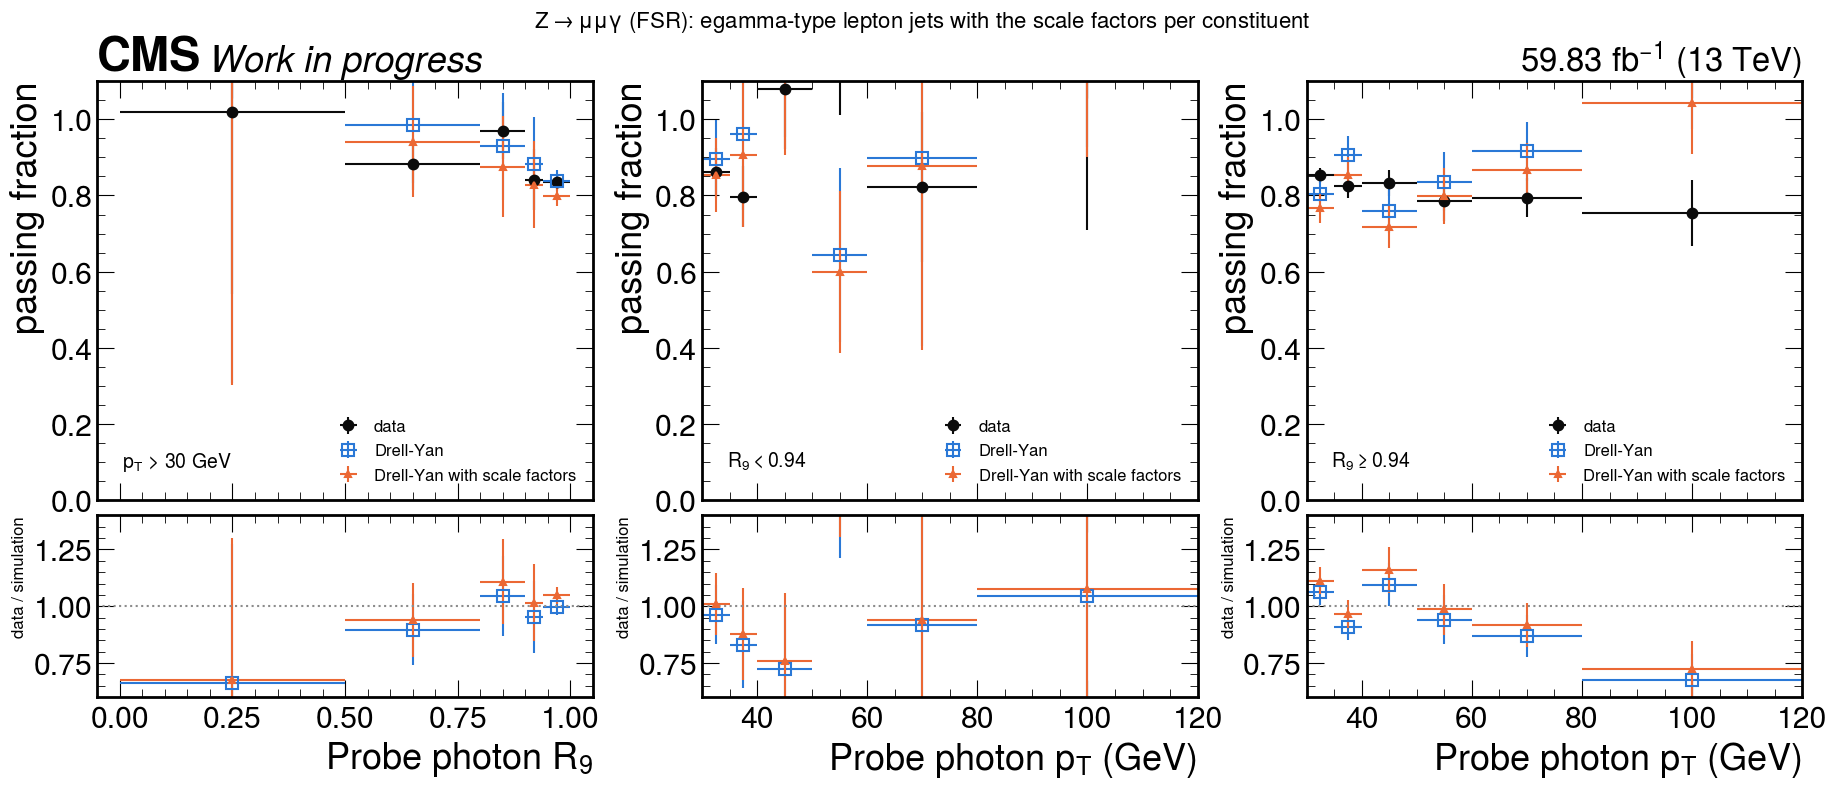

Z -> mumu gamma, photons above 30 GeV               : data/simulation 0.9909 +- 0.0386 without, 1.0438 +- 0.0407 with scale factors (shifts: electron_reco -0.0004/+0.0004, photon_pixel_veto -0.0029/+0.0029)


Z -> mumu gamma, photons 30 to 60 GeV               : data/simulation 1.0031 +- 0.0408 without, 1.0570 +- 0.0430 with scale factors (shifts: electron_reco -0.0004/+0.0004, photon_pixel_veto -0.0029/+0.0029)


Z -> mumu gamma, photons above 60 GeV               : data/simulation 0.8517 +- 0.1156 without, 0.8937 +- 0.1214 with scale factors (shifts: electron_reco -0.0006/+0.0006, photon_pixel_veto -0.0022/+0.0022)


Z -> mumu gamma, converted photons above 30 GeV     : data/simulation 0.9386 +- 0.1001 without, 0.9877 +- 0.1053 with scale factors (shifts: electron_reco -0.0009/+0.0009, photon_pixel_veto -0.0027/+0.0027)


Z -> mumu gamma, converted photons 30 to 60 GeV     : data/simulation 0.9466 +- 0.1033 without, 0.9980 +- 0.1089 with scale factors (shifts: electron_reco -0.0008/+0.0008, photon_pixel_veto -0.0028/+0.0028)


Z -> mumu gamma, converted photons above 60 GeV     : data/simulation 0.8297 +- 0.4082 without, 0.8512 +- 0.4188 with scale factors (shifts: electron_reco -0.0022/+0.0022, photon_pixel_veto -0.0007/+0.0007)


Z -> mumu gamma, unconverted photons above 30 GeV   : data/simulation 1.0118 +- 0.0350 without, 1.0662 +- 0.0369 with scale factors (shifts: electron_reco -0.0001/+0.0001, photon_pixel_veto -0.0030/+0.0030)


Z -> mumu gamma, unconverted photons 30 to 60 GeV   : data/simulation 1.0263 +- 0.0376 without, 1.0811 +- 0.0396 with scale factors (shifts: electron_reco -0.0002/+0.0002, photon_pixel_veto -0.0030/+0.0030)


Z -> mumu gamma, unconverted photons above 60 GeV   : data/simulation 0.8589 +- 0.0852 without, 0.9091 +- 0.0902 with scale factors (shifts: electron_reco +0.0001/-0.0001, photon_pixel_veto -0.0028/+0.0029)


In [4]:
spec_f = SPECS[FSR]
fig, axes = plt.subplots(2, 3, figsize=(22, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05, "wspace": 0.22})
panels = ((0, "probe_r9", ABOVE30, r"$p_T$ > 30 GeV"), (1, "probe_pt", CONVERTED, r"$R_9 < 0.94$"),
          (2, "probe_pt", UNCONVERTED, r"$R_9 \geq 0.94$"))
for col, axis, sel, text in panels:
    results = compare(data[FSR], dy[FSR], spec_f, axis, sel, reference="Drell-Yan")
    sysstudy.plot_efficiency_comparison(results, ["Drell-Yan", "Drell-Yan with scale factors"], axes[0, col], axes[1, col])
    axes[0, col].text(0.05, 0.08, text, transform=axes[0, col].transAxes, fontsize=14)
    axes[0, col].legend(fontsize=12, loc="lower right")
    tables[(FSR, axis, text)] = sysstudy.efficiency_table(results, "Drell-Yan with scale factors")
    print(f"{FSR}, {text}, against {axis}:  data | Drell-Yan with scale factors | ratio")
    for lo, hi, d, de, s, se, r, re in tables[(FSR, axis, text)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
for col in (1, 2):
    axes[1, col].set_xlim(30, 120)   # below 30 GeV no probe passes: the lepton-jet threshold
fig.suptitle(r"$Z \to \mu\mu\gamma$ (FSR): egamma-type lepton jets with the scale factors per constituent", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress")
save(fig, "closure_zmmg_fsr")
plt.show()

PT_RANGES = {"above 30 GeV": ABOVE30, "30 to 60 GeV": {"probe_pt": slice(hist.loc(30), hist.loc(60), sum)},
             "above 60 GeV": {"probe_pt": slice(hist.loc(60), None, sum)}}
for photons, r9 in (("photons", {}), ("converted photons", CONVERTED), ("unconverted photons", UNCONVERTED)):
    for range_name, sel in PT_RANGES.items():
        name = f"Z -> mumu gamma, {photons} {range_name}"
        closure[name] = sysstudy.corrected_ratios(data[FSR], dy[FSR], spec_f, {**sel, **r9})
        report(name, closure[name])

**Interpretation.** The egamma factors lower the Drell-Yan passing fraction by about 5%, mostly the
photon pixel-seed veto (0.964 per barrel photon), so for photons above 30 GeV data/Drell-Yan moves from
0.991 ± 0.039 to 1.044 ± 0.041. With the factors it is 1.066 ± 0.037 for unconverted and
0.988 ± 0.105 for converted photons, 1.057 ± 0.043 from 30 to 60 GeV and 0.894 ± 0.121 above 60 GeV.
The largest departure from one is two standard deviations (unconverted photons from 30 to 60 GeV,
1.081 ± 0.040). The precision, about 4% above 30 GeV, is set by the simulated Drell-Yan sample, whose
uncertainty is larger than that of the data.

## 4. DSA muons: the scale factor on its own measurement and on collimated pairs

The $Z \to \mu\mu$ tag and probe with Mu37_TkMu27, the measurement the scale factor comes from, with
the scale factor evaluated at each DSA muon's own $p_T$ and $|\eta|$: a check that it is applied as
measured. Then the $J/\psi$ pairs whose two muons both have a DSA muon (analysis triggers, the only
trigger their histogram holds), weighted by the product of the two scale factors: two collimated
DSA muons, as a displaced dark photon gives them.

$Z \to \mu\mu$, Mu37_TkMu27, against probe_pt:  data | Drell-Yan with scale factors | ratio
   10-20: 0.660 +- 0.032 | 0.692 +- 0.018 | 0.954 +- 0.053
   20-30: 0.723 +- 0.001 | 0.723 +- 0.001 | 1.000 +- 0.002
   30-40: 0.713 +- 0.000 | 0.713 +- 0.000 | 1.000 +- 0.001
   40-50: 0.703 +- 0.000 | 0.704 +- 0.000 | 0.999 +- 0.000
   50-60: 0.694 +- 0.001 | 0.693 +- 0.000 | 1.001 +- 0.001
   60-80: 0.683 +- 0.001 | 0.682 +- 0.001 | 1.000 +- 0.002
   80-120: 0.645 +- 0.002 | 0.649 +- 0.001 | 0.994 +- 0.004
   120-200: 0.593 +- 0.004 | 0.603 +- 0.002 | 0.984 +- 0.008
$Z \to \mu\mu$, Mu37_TkMu27, against probe_abseta:  data | Drell-Yan with scale factors | ratio
   0-0.9: 0.747 +- 0.000 | 0.748 +- 0.000 | 0.999 +- 0.000
   0.9-1.2: 0.657 +- 0.001 | 0.657 +- 0.000 | 1.000 +- 0.001
   1.2-2.1: 0.726 +- 0.000 | 0.724 +- 0.000 | 1.002 +- 0.001
   2.1-2.4: 0.428 +- 0.001 | 0.433 +- 0.000 | 0.988 +- 0.002
$J/\psi$ pairs, two DSA muons, against probe_pt:  data | simulation with scale factors | ratio


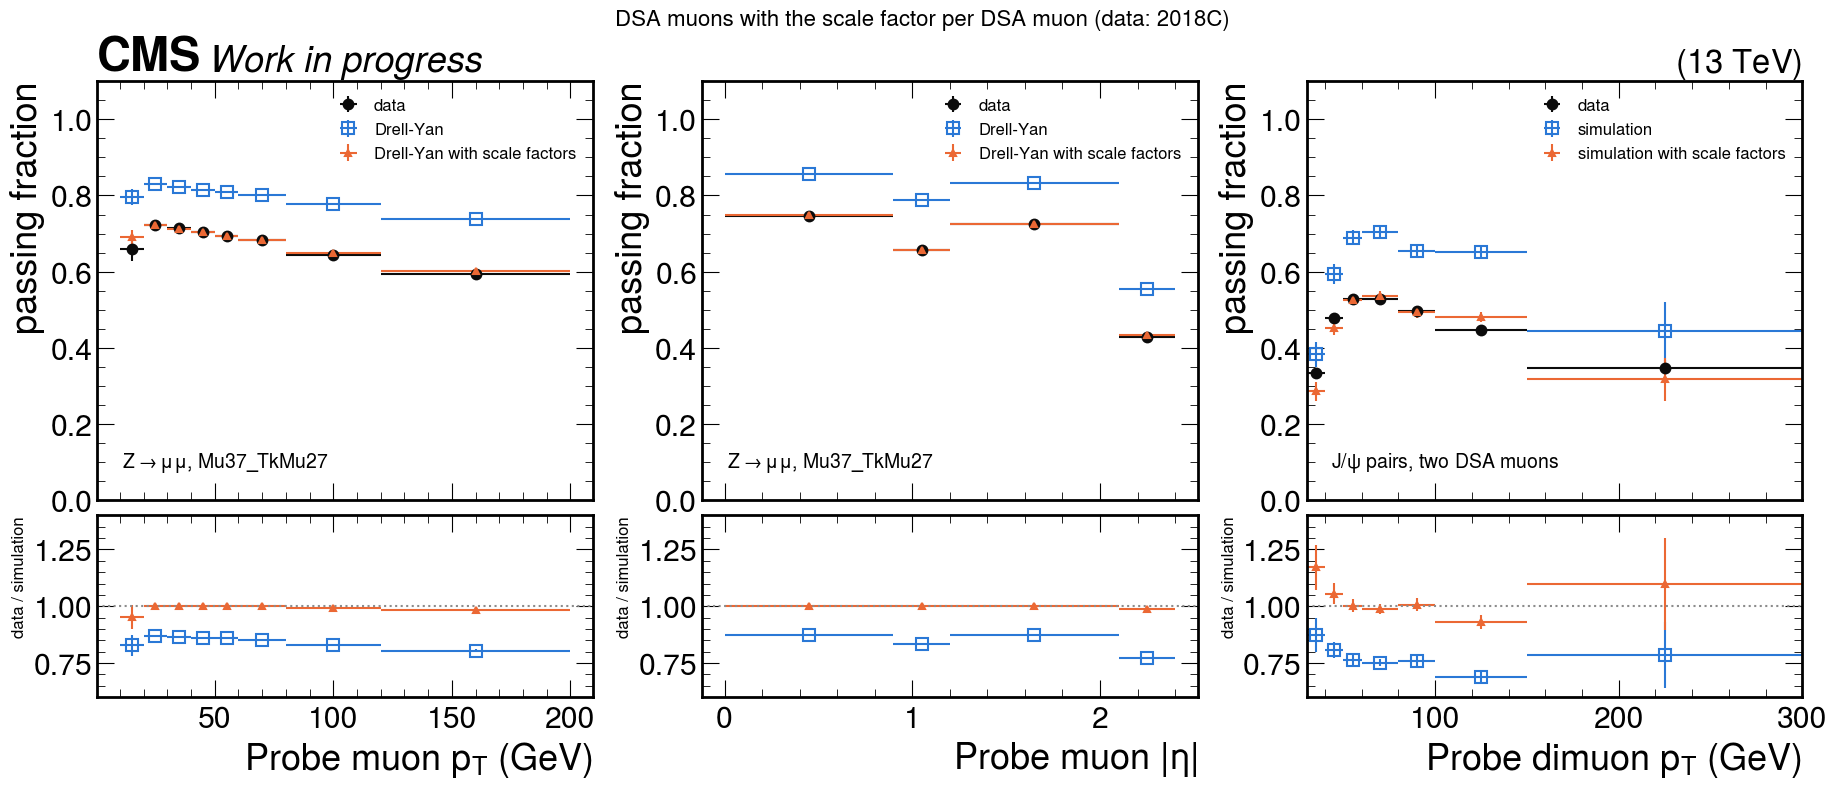

Z -> mumu, DSA, Mu37_TkMu27, all probes             : data/simulation 0.8621 +- 0.0003 without, 0.9991 +- 0.0003 with scale factors (shifts: dsa_muon_id -0.0240/+0.0252)
J/psi pairs, two DSA muons, pT > 40 GeV             : data/simulation 0.7668 +- 0.0127 without, 1.0078 +- 0.0166 with scale factors (shifts: dsa_muon_id -0.0527/+0.0571)
J/psi pairs, two DSA muons, pT > 100 GeV            : data/simulation 0.7021 +- 0.0282 without, 0.9535 +- 0.0382 with scale factors (shifts: dsa_muon_id -0.0387/+0.0411)
J/psi pairs, two DSA muons, pT > 40 GeV, dR 0.03 to 0.05: data/simulation 0.7223 +- 0.0599 without, 1.0055 +- 0.0833 with scale factors (shifts: dsa_muon_id -0.0357/+0.0376)


In [5]:
spec_z, spec_jd = SPECS[Z_DSA], SPECS[JPSI_DSA]
d_z = sysstudy.select_trigger(data[Z_DSA], "trig_tkmu", probe_tight=sum)
s_z = sysstudy.select_trigger(dy[Z_DSA], "trig_tkmu", probe_tight=sum)
d_j = sysstudy.select_trigger(data[JPSI_DSA], "trig_analysis")
s_j = sysstudy.select_trigger(sim[JPSI_DSA], "trig_analysis")
fig, axes = plt.subplots(2, 3, figsize=(22, 8), sharex="col",
                         gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05, "wspace": 0.22})
panels = ((0, d_z, s_z, spec_z, "probe_pt", {}, ("passing", (1,)), "Drell-Yan", r"$Z \to \mu\mu$, Mu37_TkMu27"),
          (1, d_z, s_z, spec_z, "probe_abseta", {}, ("passing", (1,)), "Drell-Yan", r"$Z \to \mu\mu$, Mu37_TkMu27"),
          (2, d_j, s_j, spec_jd, "probe_pt", {}, TWO, "simulation", r"$J/\psi$ pairs, two DSA muons"))
for col, d_h, s_h, spec, axis, sel, passing, reference, text in panels:
    results = compare(d_h, s_h, spec, axis, sel, passing, reference=reference)
    sysstudy.plot_efficiency_comparison(results, [reference, f"{reference} with scale factors"], axes[0, col], axes[1, col])
    axes[0, col].text(0.05, 0.08, text, transform=axes[0, col].transAxes, fontsize=14)
    axes[0, col].legend(fontsize=12, loc="upper right")
    axes[0, col].set_ylim(0, 1.1)
    axes[1, col].set_ylim(0.6, 1.4)
    tables[(spec["label"], axis)] = sysstudy.efficiency_table(results, f"{reference} with scale factors")
    print(f"{text}, against {axis}:  data | {reference} with scale factors | ratio")
    for lo, hi, d, de, s, se, r, re in tables[(spec["label"], axis)]:
        print(f"   {lo:g}-{hi:g}: {d:.3f} +- {de:.3f} | {s:.3f} +- {se:.3f} | {r:.3f} +- {re:.3f}")
axes[1, 2].set_xlim(30, 300)
fig.suptitle("DSA muons with the scale factor per DSA muon (data: 2018C)", fontsize=16, y=0.97)
pt.cms_label(axes[0], data=True, text="Work in progress", lumi=None)
save(fig, "closure_dsa")
plt.show()

for name, d_h, s_h, spec, sel, passing in (
        ("Z -> mumu, DSA, Mu37_TkMu27, all probes", d_z, s_z, spec_z, {}, ("passing", (1,))),
        ("J/psi pairs, two DSA muons, pT > 40 GeV", d_j, s_j, spec_jd, ABOVE40, TWO),
        ("J/psi pairs, two DSA muons, pT > 100 GeV", d_j, s_j, spec_jd, {"probe_pt": slice(hist.loc(100), None, sum)}, TWO),
        ("J/psi pairs, two DSA muons, pT > 40 GeV, dR 0.03 to 0.05", d_j, s_j, spec_jd,
         {**ABOVE40, "probe_dR": slice(hist.loc(0.03), hist.loc(0.05), sum)}, TWO)):
    closure[name] = sysstudy.corrected_ratios(d_h, s_h, spec, sel, passing)
    report(name, closure[name])

**Interpretation.** On its own measurement the scale factor gives data/simulation 0.999 (0.862
without), and 0.98 to 1.00 in every $p_T$ and $|\eta|$ bin above 20 GeV: it is applied as measured.
The small differences come from evaluating it at the DSA muon's own $p_T$ and $|\eta|$ and from the
merged bins. For $J/\psi$ pairs whose two muons both have a DSA muon, the product of the two factors
brings the ratio from 0.767 ± 0.013 to 1.008 ± 0.017 above 40 GeV, 1.006 ± 0.083 for $\Delta R$ from
0.03 to 0.05 and 0.954 ± 0.038 above 100 GeV; bin by bin from 40 to 150 GeV it lies between 0.93 and
1.06. A factor per DSA muon describes two collimated DSA muons.

## 5. The additional systematic per lepton jet

For each regime, the ratio with the corrections applied over the measured range above the turn-on,
and in the measured bins nearest to the signal. A nearest bin that differs from the whole range by
more than two standard deviations sets the value instead. The size per lepton jet is
$\max(|1 - r|, \sigma_r)$, and the muon-type term takes the larger of its two regimes (PF muons and
DSA muons), since a muon-type lepton jet of the signal can hold either.

In [6]:
REGIMES = {
    "muon-type, PF muons": ("J/psi, pT > 50 GeV",
                            ["J/psi, pT > 150 GeV", "J/psi, pT > 50 GeV, dR 0.03 to 0.05",
                             "J/psi, pT > 50 GeV, vertex L_xy 2 to 15 cm"]),
    "muon-type, DSA muons": ("J/psi pairs, two DSA muons, pT > 40 GeV",
                             ["J/psi pairs, two DSA muons, pT > 100 GeV",
                              "J/psi pairs, two DSA muons, pT > 40 GeV, dR 0.03 to 0.05"]),
    "egamma-type": ("Z -> mumu gamma, photons above 30 GeV", ["Z -> mumu gamma, photons above 60 GeV"]),
}
sizes = {}
for regime, (whole, nearest) in REGIMES.items():
    r, u = closure[whole]["nominal"]
    chosen, why = whole, "the whole range"
    for name in nearest:
        rn, un = closure[name]["nominal"]
        pull = (rn - r) / np.hypot(un, u)
        print(f"{regime:22s} {name:56s}: {rn:.4f} +- {un:.4f}, {pull:+.1f} standard deviations from the whole range")
        if abs(pull) > 2 and sysstudy.closure_size(rn, un) > sysstudy.closure_size(*closure[chosen]["nominal"]):
            chosen, why = name, "a nearest bin that disagrees"
    sizes[regime] = {"region": chosen, "ratio": closure[chosen]["nominal"][0], "uncertainty": closure[chosen]["nominal"][1],
                     "size": sysstudy.closure_size(*closure[chosen]["nominal"])}
    print(f"{regime:22s} -> {chosen} ({why}): r = {sizes[regime]['ratio']:.4f} +- {sizes[regime]['uncertainty']:.4f}, "
          f"size {100 * sizes[regime]['size']:.1f}% per lepton jet\n")
per_lj = {"muon": max(sizes["muon-type, PF muons"]["size"], sizes["muon-type, DSA muons"]["size"]),
          "egamma": sizes["egamma-type"]["size"]}
print("systematics.yaml:")
for name, lj_type in (("CMS_ljreco_mu", "muon"), ("CMS_ljreco_egm", "egamma")):
    print(f"{name}:\n  per_lj: {per_lj[lj_type]:.3f}\n  lj_type: {lj_type}")

muon-type, PF muons    J/psi, pT > 150 GeV                                     : 1.0009 +- 0.0599, -0.1 standard deviations from the whole range
muon-type, PF muons    J/psi, pT > 50 GeV, dR 0.03 to 0.05                     : 1.0104 +- 0.0322, +0.0 standard deviations from the whole range
muon-type, PF muons    J/psi, pT > 50 GeV, vertex L_xy 2 to 15 cm              : 1.0167 +- 0.0068, +0.9 standard deviations from the whole range
muon-type, PF muons    -> J/psi, pT > 50 GeV (the whole range): r = 1.0089 +- 0.0063, size 0.9% per lepton jet

muon-type, DSA muons   J/psi pairs, two DSA muons, pT > 100 GeV                : 0.9535 +- 0.0382, -1.3 standard deviations from the whole range
muon-type, DSA muons   J/psi pairs, two DSA muons, pT > 40 GeV, dR 0.03 to 0.05: 1.0055 +- 0.0833, -0.0 standard deviations from the whole range
muon-type, DSA muons   -> J/psi pairs, two DSA muons, pT > 40 GeV (the whole range): r = 1.0078 +- 0.0166, size 1.7% per lepton jet

egamma-type            Z -> mu

**Interpretation.** No nearest region differs from its whole range by more than 1.3 standard
deviations, so each regime takes its whole range: 0.9% for PF muons (1.009 ± 0.006), 1.7% for DSA
muons (1.008 ± 0.017, set by its statistical uncertainty) and 4.4% for egamma-type lepton jets
(1.044 ± 0.041). The muon-type term takes the larger of its regimes, 1.7%, which also covers the most
displaced $J/\psi$ pairs (1.017 ± 0.007 from 2 to 15 cm). The egamma-type lepton jets of the signal lie
above 120 GeV, beyond the photons measured here; the bin above 60 GeV, nearest to them, gives
0.894 ± 0.121, consistent with the whole range, which is three times more precise. In the cards
`CMS_ljreco_mu` is 1.7% per muon-type lepton jet (1.017 in 2mu2e, 1.034 in 4mu) and `CMS_ljreco_egm`
4.4% per egamma-type one (2mu2e only).

## 6. What it gives

- With the scale factors per constituent applied, the simulation describes the lepton-jet efficiency
  of the control samples to 1 to 2% for muon-type lepton jets, and within the 4% precision of the
  egamma-type ones: 1.009 ± 0.006 for $J/\psi$ above 50 GeV (lepton jets of two PF muons, or of one PF
  and one DSA muon), 1.017 ± 0.003 at vertex displacements from 1 mm to 15 cm, 1.008 ± 0.017 for two
  collimated DSA muons, and 1.044 ± 0.041 for FSR photons above 30 GeV.
- The additional systematic is 1.7% per muon-type and 4.4% per egamma-type lepton jet
  (`CMS_ljreco_mu`, `CMS_ljreco_egm`, kind `per_lj` in [`systematics.yaml`](systematics.yaml)):
  the muon type from the precision of the DSA pairs, which also covers the displaced $J/\psi$, the
  egamma type from the departure of the FSR photons, which their 4.1% precision nearly matches.
- The control samples have no probes beyond 15 cm, above 300 GeV, below $\Delta R$ = 0.03 for muon
  pairs, or above 120 GeV for photons ([`11_lj_coverage_map.ipynb`](11_lj_coverage_map.ipynb)); there
  the sizes of the measured regions apply. Notebooks 03 to 05 put both terms into the limits.

In [7]:
with open(WORK / "closure.json", "w") as f:
    json.dump({"ratios": {name: {c: list(v) for c, v in ratios.items()} for name, ratios in closure.items()},
               "regimes": sizes, "per_lj": per_lj,
               "tables": {" | ".join(key): [list(map(float, row)) for row in table] for key, table in tables.items()}},
              f, indent=1)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v4_results
